<a id="chapter-15"></a>

# Chapter 15 · Continuous Action Space / 连续动作空间

[← 学习索引](README.md) · [项目主页](../README.md) · [跳到本章扩展](#extension)

> 学习方式：按顺序读到代码单元，先预测输出再运行。正文只保留理解主线；非必要的证明、变体与工程细节放在[扩展](#extension)。

**学完本章，你应该能：**

- 理解连续策略与动作缩放
- 掌握 DDPG actor/critic 与 target update
- 认识 D4PG 的 distributional critic

**开始前最好已经会：**

- 理解 actor-critic
- 会对复合函数使用链式法则
- 了解 replay buffer 与 target network


## 原书覆盖地图

| 原书主题 | 本 notebook 对应位置 | 深度 |
|---|---|---|
| Why continuous space? | 离散/连续动作差异 | 详细 |
| A2C method | Gaussian policy 与连续采样 | 详细 |
| Deep deterministic policy gradients | DDPG 推导与源码 | 详细 |
| Distributional policy gradients | D4PG 投影与源码 | 详细 |
| Things to try | 练习与扩展 | 实践 |

“详细”表示正文包含推导或完整数据流；“源码路线”表示正文解释职责并链接真实实现；次要变体保留在扩展区。这样可以明确看到本章没有把原书哪个主题悄悄跳过。


## 0. 先想一个问题

方向盘角度有无限多种可能，无法像 DQN 一样对所有动作取 max。怎样让网络直接给出最优连续动作？

> 不必立刻回答。读完本章后再回到这里，尝试用两三句话作答。


## 1. 心智模型：先知道信息怎样流动

连续动作无法逐个枚举。随机策略常输出 Gaussian 参数；DDPG 用确定性 actor 直接产生动作，并由 critic 提供梯度。

学习时始终追问三件事：**当前已知什么？要估计什么？哪个量会被更新？** 这比先背算法名称更重要。


## 2. 符号表：先统一语言

| 符号/名称 | 含义 | 阅读时怎么想 |
|---|---|---|
| $\mu_\theta(s)$ | 确定性 actor | 直接输出连续动作 |
| $Q_\phi(s,a)$ | critic | 评价状态-动作对 |
| $\theta^-,\phi^-$ | target 参数 | 缓慢跟随在线网络 |
| $\tau$ | soft-update 比例 | 通常远小于 1 |
| $[l,h]$ | 环境动作范围 | 网络输出必须映射到该范围 |

第一次阅读只需认识这些符号；看到公式时再回来查，不要求一次背完。


## 3. 分步推导：公式不是凭空出现的


### 1. critic 的目标

DDPG 是 off-policy actor-critic。给定 replay transition：

$$y=r+\gamma(1-d)Q_{\phi^-}(s',\mu_{\theta^-}(s'))$$

critic 最小化 $(Q_\phi(s,a)-y)^2$，形式与 DQN 相似，只是下一动作由 target actor 产生。

### 2. actor 怎样得到梯度

actor 希望最大化 critic 对其动作的评分：

$$J(\theta)=\mathbb E_s[Q_\phi(s,\mu_\theta(s))]$$

链式法则给出

$$\nabla_\theta J=\mathbb E[\nabla_aQ_\phi(s,a)|_{a=\mu(s)}\nabla_\theta\mu_\theta(s)]$$

自动微分会穿过 critic 的动作输入回到 actor；实现时最小化 `-critic(s, actor(s)).mean()`。

### 3. soft target update

$$\theta^-\leftarrow(1-\tau)\theta^-+\tau\theta$$

$\tau=1$ 等价于硬同步；小 $\tau$ 是指数移动平均，使 target 平滑变化。

### 4. 动作缩放

若 actor 用 `tanh` 输出 $u\in[-1,1]$，映射到 $[l,h]$：
$a=l+(u+1)(h-l)/2$。若各动作维度范围不同，`low/high` 必须是向量。


## 4. 手算一个最小例子


动作范围 $[-2,4]$：区间中心为 1，半宽为 3。因此 $u=-1,0,1$ 映射为 $-2,1,4$。

target 参数原为 2，online 参数更新到 4，$\tau=0.05$：新 target 为 $0.95\times2+0.05\times4=2.1$，只移动一小步。


> 手算的目的不是练算术，而是给公式建立可检查的直觉。代码输出与手算矛盾时，先停下来找原因。


## 5. 本章公式卡


### DDPG 核心

critic 目标：$y=r+\gamma(1-d)Q_{\phi^-}(s',\mu_{\theta^-}(s'))$。

actor 目标：$J(\theta)=\mathbb E_s[Q_\phi(s,\mu_\theta(s))]$，训练时最小化 $-J$。

soft update：
$$\theta^-\leftarrow\tau\theta+(1-\tau)\theta^-$$

网络常输出 $u\in[-1,1]$，再映射到环境区间 $[l,h]$：$a=l+(u+1)(h-l)/2$。


这张卡用于复习，不替代上一节的推导。


## 6. 公式 ↔ 代码逐项对照

| 数学对象/步骤 | 代码对应 | 作用与形状提示 |
|---|---|---|
| $u\in[-1,1]$ | actor 的 `tanh` 输出 | 归一化动作 |
| $a\in[l,h]$ | `scale_action(unit, low, high)` | 环境实际动作 |
| $\theta,\theta^-$ | `online`, `target` | 在线与目标模块 |
| $(1-\tau)\theta^-+\tau\theta$ | `target_p.mul_(1-tau).add_(online_p, alpha=tau)` | 原地 soft update |
| actor loss | `-critic(states, actor(states)).mean()` | 经 critic 动作梯度更新 actor |

**从公式过渡到代码时：**动作缩放和 target soft update 都是短小但常出错的基础操作。


## 7. 动手实验

运行前先做三件事：

1. 根据手算例子预测关键输出的方向或数量级；
2. 找到上一张表中的每个代码变量；
3. 运行后只改一个变量，观察结果是否符合公式。


In [1]:
import torch

def scale_action(unit_action, low, high):
    return low + (unit_action + 1.0) * 0.5 * (high - low)

unit = torch.tensor([-1.0, 0.0, 1.0])
print("scaled:", scale_action(unit, low=-2.0, high=4.0))

online = torch.nn.Linear(2, 1)
target = torch.nn.Linear(2, 1)
target.load_state_dict(online.state_dict())
with torch.no_grad():
    online.weight.add_(1.0)  # 模拟一次训练更新
    tau = 0.05
    for target_p, online_p in zip(target.parameters(), online.parameters()):
        target_p.mul_(1 - tau).add_(online_p, alpha=tau)
print("soft-updated target weight:", target.weight)


scaled: tensor([-2.,  1.,  4.])
soft-updated target weight: Parameter containing:
tensor([[-0.3444,  0.2213]], requires_grad=True)


### 怎样读运行结果

缩放结果应为 `[-2,1,4]`。soft update 后 target 只吸收 online 变化的 5%。项目代码中再寻找 critic target、actor loss 与 exploration noise。

如果结果不符合描述，先检查随机种子、终止 mask、数组 shape 和依赖版本，而不是马上调超参数。


## 8. 完整算法：把前面的零件装起来


```text
DDPG/D4PG：
初始化 actor μθ、critic Qφ 及 target 副本、replay
与环境交互：a = scale(μθ(s) + exploration_noise)
采样 batch
with no_grad:
    a' = μθ-(s')
    y = r_n + γ^n * non_terminal * Qφ-(s', a')
critic: 回归 y（D4PG 改为 categorical distribution projection）
actor: 最小化 -Qφ(s, μθ(s))
soft-update 两个 target
```

连续 A2C 则让 actor 输出 Gaussian 的均值和方差，on-policy 采样动作；DDPG 是 deterministic、off-policy，并依赖 replay 和探索噪声。


## 9. 第二个验证实验

第一个实验负责建立直觉；下面这个实验专门验证一个容易写错的性质。它仍然保持轻量，目的是让你能用断言判断实现是否符合公式。


In [2]:
import numpy as np

# 简化 categorical projection：把标量 2.3 的质量分到相邻 atoms 2 和 3。
atoms = np.arange(0., 5.)
value = 2.3
lower, upper = int(np.floor(value)), int(np.ceil(value))
projected = np.zeros_like(atoms)
projected[lower] += upper - value
projected[upper] += value - lower
print("atoms:", atoms, "projected mass:", projected)
assert np.isclose(projected.sum(), 1.0)


atoms: [0. 1. 2. 3. 4.] projected mass: [0.  0.  0.7 0.3 0. ]


## 10. 项目源码精读路线

| 文件 | 重点类/函数 | 阅读目的 |
|---|---|---|
| [`01_check_env.py`](../Chapter15/01_check_env.py) | 环境检查 | 先确认 observation/action bounds |
| [`02_train_a2c.py`](../Chapter15/02_train_a2c.py) | 连续 A2C | Gaussian 分布、log_prob、entropy |
| [`04_train_ddpg.py`](../Chapter15/04_train_ddpg.py) | DDPG trainer | replay、双 target、actor/critic 更新 |
| [`06_train_d4pg.py`](../Chapter15/06_train_d4pg.py) | D4PG trainer | n-step 与分布投影 |
| [`model.py`](../Chapter15/lib/model.py) | actor/critic/distributional critic | 输出范围与 shape |
| [`common.py`](../Chapter15/lib/common.py) | unpack_batch_a2c / unpack_batch_ddqn | episode 边界与 bootstrap 的 batch 整理 |

<details>
<summary>为什么按这个顺序读</summary>

连续 A2C 要把每个动作维度的 log-prob 求和，entropy 也按维度汇总；标准差应通过 `softplus`/exp 等保证为正。DDPG 训练 actor 时 critic 参数可以参与前向但不应被 actor optimizer 更新。D4PG 的 categorical projection 与第 8 章相似，但 target atom 加上 n-step reward 后还要乘 $\gamma^n$，并处理连续动作的 target actor。

</details>

notebook 的实验负责隔离原理，仓库脚本负责完整环境、日志和训练。阅读时拿着第 6 节对照表寻找同一数学对象；变量名可以不同，数据语义不能不同。


## 11. 训练曲线、调参与失败复盘

**本章主诊断指标：**连续策略在二次奖励上的回报

下面的曲线来自可重复运行的微型训练，不是手工填写的数据。它用于学习“该看什么、怎样判断”；原书规模的训练应使用上一节链接的项目脚本，并同时保存配置、随机种子、环境步数和 wall-clock。

> 曲线阅读顺序：先看任务指标，再看优化指标，最后看资源指标。单次最好成绩不能代替多随机种子均值与波动。


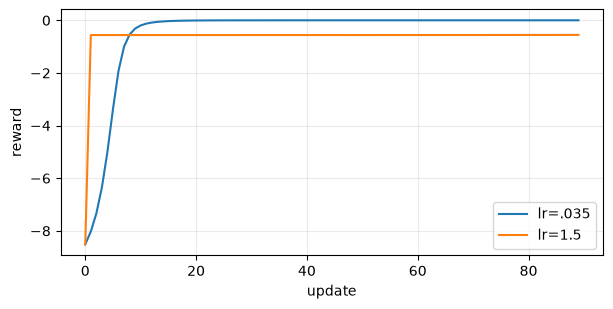

final actions: 1.25 1.995 target: 1.25


In [3]:
import numpy as np
import matplotlib.pyplot as plt

def plot_curve(series, title, ylabel, *, window=1):
    # Plot raw measurements and an optional moving average.
    values = np.asarray(series, dtype=float)
    x = np.arange(1, len(values) + 1)
    plt.figure(figsize=(7, 3.2))
    plt.plot(x, values, alpha=0.35, label="raw")
    if window > 1 and len(values) >= window:
        smooth = np.convolve(values, np.ones(window) / window, mode="valid")
        plt.plot(x[window - 1:], smooth, linewidth=2, label=f"MA({window})")
    plt.title(title)
    plt.xlabel("iteration / episode")
    plt.ylabel(ylabel)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.show()
    plt.close()


target_action = 1.25

def train_actor(lr):
    theta, history = -1.2, []
    for _ in range(90):
        action = 2 * np.tanh(theta)
        reward = -(action - target_action) ** 2
        # d reward / d theta，展示 deterministic policy gradient 的最小形式。
        grad = -2 * (action - target_action) * 2 * (1 - np.tanh(theta) ** 2)
        theta += lr * grad
        history.append(reward)
    return history, 2 * np.tanh(theta)

stable, action_ok = train_actor(.035)
fast, action_fast = train_actor(1.5)
plt.figure(figsize=(7, 3.2)); plt.plot(stable, label="lr=.035"); plt.plot(fast, label="lr=1.5")
plt.xlabel("update"); plt.ylabel("reward"); plt.grid(alpha=.25); plt.legend(); plt.show(); plt.close()
print("final actions:", round(action_ok, 3), round(action_fast, 3), "target:", target_action)


### 曲线怎么读

稳定学习率应平滑靠近最优回报 0；大学习率可能震荡或在 tanh 饱和区停滞。连续控制要同时观察 action 分布和 critic Q，不能只看 episode return。

### 调参过程：一次只改变一个因素

- 先检查动作缩放是否覆盖环境 bounds。
- 从 critic loss/Q target 稳定性开始，再分别调 actor/critic learning rate。
- 最后调探索噪声、target soft-update $\tau$ 和 n-step，记录多种子。

### 失败案例复盘

- actor 输出 `tanh` 后没有缩放到真实 action range。
- target action 没有裁剪，环境收到非法动作。
- critic Q 值不断增大而回报不升，属于 extrapolation/bootstrapping 失稳。

遇到失败时先保存配置和原始曲线，复现后再修；不要一边改环境、一边改网络、一边改学习率，否则无法知道修复来自哪里。


## 12. 实用技巧与常见坑

- 同时检查 environment action bounds 和策略输出范围。
- critic 更新时 target actor/critic 都应停止梯度。
- 探索噪声的尺度要相对于动作区间设定。

这些不是附属知识：RL 结果方差大，很多“算法没学会”其实是终止语义、shape、数据泄漏或评估方式错误。


## 13. 动手练习

把动作区间改为 `[2, 5]`，验证 -1、0、1 分别映射到哪里。

<details>
<summary>完成标准（做完再展开）</summary>

不只给出结果；还应说明改了哪个变量、对应哪条公式、变化是否符合预期，并写出至少一个边界情况。若能用 `assert` 固化结论更好。
</details>


## 14. 练习参考答案

<details>
<summary>完成练习后再展开</summary>

区间 `[2,5]` 的中心是 3.5、半宽 1.5，因此 unit action -1/0/1 映射到 2/3.5/5。实现应支持向量 low/high，并在送入环境前断言所有维度位于 bounds 内。

</details>


## 15. 合上 notebook 后，脑中应留下什么

- 连续动作不能枚举，actor 直接产生动作。
- critic 学 Bellman target，actor 沿 critic 对动作的梯度上升。
- target actor/critic 都要停止 target 分支梯度。
- 动作范围和探索噪声必须按每个维度校准。

回到开头的那个问题。现在请不用公式，向一个没学过本章的人解释答案；能讲清楚，才算真正理解。


## 16. 两分钟自测

**问题：**训练 actor 时为什么不能把 critic 输出 detach？target actor 的输出为什么又要停止梯度？

<details>
<summary>展开答案</summary>

actor 需要梯度穿过 critic 的动作输入才能知道如何改变动作；target 分支只构造稳定监督信号，不应参与当前反向传播。
</details>


## 17. 与前后章节连接

第 16 章继续使用连续控制环境，对比 PPO、TRPO、ACKTR 和 SAC 的稳定更新方式。

学习强化学习最怕把算法记成孤岛。每章结束时，都应能说明本章复用了前面的什么，又为后面准备了什么。


<a id="extension"></a>

## 扩展：主线学完后再深挖

D4PG 使用分布式 critic、n-step return 与分布式采样；TD3 用双 critic 和延迟 actor 更新降低过估计。

扩展内容用于建立知识地图，不要求第一次学习就掌握。先确保能完成上面的两分钟自测，再决定是否继续。

[↑ 回到开头](#chapter-15) · [← 学习索引](README.md)
